# Day 6 : Exploratory Data Analysis of Processing Energy Consumption

Pengolahan bijih & mineral membutuhkan **energi listrik** yang besar (penggilingan, flotasi, peleburan).

Memahami pola konsumsi energi membantu menekan biaya dan emisi. Pada Notebook ini Saya akan mengeksplorasi data konsumsi energi sebuah pabrik pemroses (proxy untuk pabrik pengolahan mineral):

- kapan pemakaian tinggi, bagaimana pengaruh jenis beban, dan kaitannya dengan emisi CO₂.

🎯 **Tujuan Pembelajaran**
> - Mengubah kolom `date` menjadi `datetime` & mengekstrak pola waktu.
> - Melakukan **resample** deret waktu (agregasi harian).
> - Membandingkan konsumsi antar kategori (`Load_Type`, `WeekStatus`, hari).
> - Membuat 3 grafik: garis harian, boxplot per beban, bar per hari.

## About the Dataset

**Steel Industry Energy Consumption** — data konsumsi listrik sebuah pabrik (pemroses logam), direkam tiap 15 menit sepanjang satu tahun. Kita pakai sebagai **proxy** pabrik pemrosesan mineral.

- **Sumber:** [Kaggle — csafrit2/steel-industry-energy-consumption](https://www.kaggle.com/datasets/csafrit2/steel-industry-energy-consumption)
- **Ukuran:** 35.040 baris × 11 kolom (35.040 = 96 rekaman/hari × 365 hari)

| Kolom | Arti |
|-------|------|
| `date` | Waktu rekaman (tiap 15 menit) |
| `Usage_kWh` | Konsumsi listrik (kWh) ← **fokus** |
| `CO2(tCO2)` | Emisi CO₂ terkait |
| `Lagging_Current_Power_Factor` | Faktor daya tertinggal |
| `NSM` | Detik sejak tengah malam (penanda jam) |
| `WeekStatus` | Hari kerja / akhir pekan |
| `Day_of_week` | Nama hari |
| `Load_Type` | Tingkat beban (Light / Medium / Maximum) |

*Konsumsi energi berkaitan langsung dengan **biaya operasi** & **jejak karbon** pengolahan bijih.*

##  Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

##  Import Dataset

In [2]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d csafrit2/steel-industry-energy-consumption
!unzip steel-industry-energy-consumption.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/csafrit2/steel-industry-energy-consumption
License(s): other
100% 484k/484k [00:00<00:00, 110MB/s]

Archive:  steel-industry-energy-consumption.zip
  inflating: Steel_industry_data.csv  


## Initial Exploration

In [4]:
df = pd.read_csv('Steel_industry_data.csv')
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  object 
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-null  float64
 7   NSM                                   35040 non-null  int64  
 8   WeekStatus                            35040 non-null  object 
 9   Day_of_week                           35040 non-null  object 
 10  Load_Type                             35040 non-null  object 
dtypes: float64(6), 

**Interpretation:**

Dataset ini berisi **35.040 baris** (sekitar **1 tahun** data per **15 menit**) dan **11 kolom** tanpa data kosong:

* **Waktu:** `date` (perlu jadi `datetime`), `NSM` (detik sejak tengah malam), `WeekStatus` (hari kerja/akhir pekan), `Day_of_week`.
* **Energi & Emisi:** `Usage_kWh` (pemakaian listrik utama) dan `CO2(tCO2)` (emisi karbon).
* **Kualitas Daya:** `Lagging/Leading_Current_Reactive..._kVarh` (daya reaktif) dan `Lagging/Leading_Current_Power_Factor` (efisiensi daya).
* **Beban:** `Load_Type` (kategori tingkat beban).

**Intinya:** Data cukup bersih untuk memprediksi `Usage_kWh`, memantau efisiensi *power factor*, dan membandingkan pola pemakaian antar waktu atau jenis beban.

## Setting Up a Time Column

Saya akan ubah `date`, lalu ekstrak jam & tanggal untuk analisis pola.

In [6]:
def siapkan_kolom_waktu(
    df: pd.DataFrame,
    date_col: str = "date",
    dayfirst: bool = True,
) -> pd.DataFrame:
    """Membersihkan kolom tanggal, mengurutkan waktu, dan mengekstrak fitur waktu dasar."""
    data = df.copy()
    data[date_col] = pd.to_datetime(data[date_col], dayfirst=dayfirst, errors="coerce")

    data = (
        data.dropna(subset=[date_col])
        .sort_values(date_col)
        .reset_index(drop=True)
    )

    dt_accessor = data[date_col].dt
    data["jam"] = dt_accessor.hour
    data["tanggal"] = dt_accessor.date

    return data


df = siapkan_kolom_waktu(df)
print(f"Rentang waktu: {df['date'].min()} -> {df['date'].max()}")
df[["date", "Usage_kWh", "Load_Type", "jam"]].head()

Rentang waktu: 2018-01-01 00:00:00 -> 2018-12-31 23:45:00


,date,Usage_kWh,Load_Type,jam
0,2018-01-01 00:00:00,3.42,Light_Load,0
1,2018-01-01 00:15:00,3.17,Light_Load,0
2,2018-01-01 00:30:00,4.00,Light_Load,0
3,2018-01-01 00:45:00,3.24,Light_Load,0
4,2018-01-01 01:00:00,3.31,Light_Load,1


## Exploratory Data Analysis & Visualization

### a) Daily energy consumption trend (daily resample)

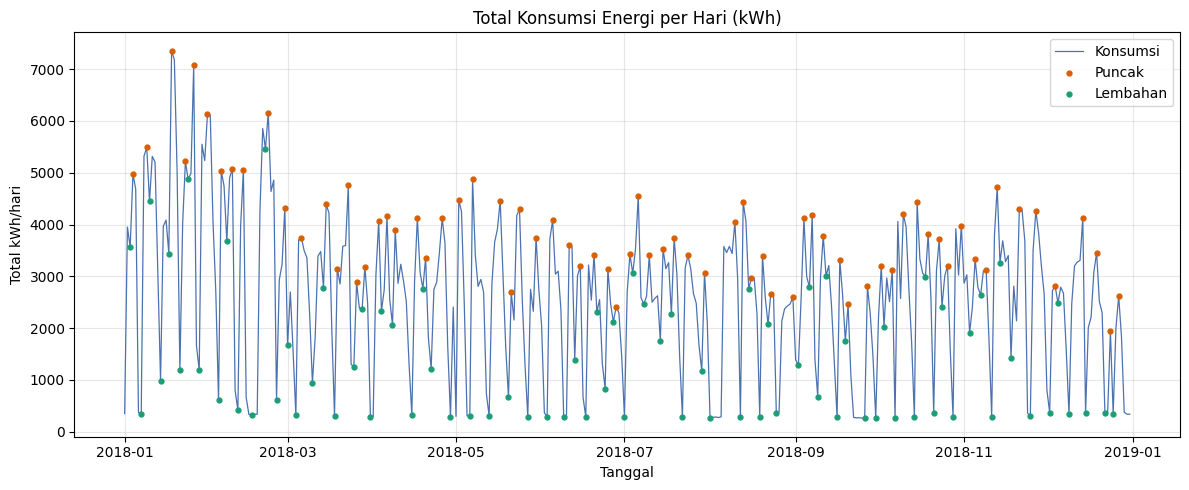

In [9]:
from scipy.signal import find_peaks

def agregasi_energi_harian(
    df: pd.DataFrame,
    date_col: str = "date",
    target_col: str = "Usage_kWh",
    freq: str = "D",
) -> pd.Series:
    """Menghitung total konsumsi energi berdasarkan interval waktu tertentu."""
    return df.set_index(date_col)[target_col].resample(freq).sum()


def plot_seri_waktu_ekstrem(
    series: pd.Series,
    title: str,
    xlabel: str,
    ylabel: str,
    figsize: tuple[int, int] = (12, 5),
    line_color: str = "#4C72B0",
    peak_color: str = "#D95F02",
    trough_color: str = "#1B9E77",
    marker_size: float = 3.5,
    prominence: float | None = None,
    distance: int = 1,
) -> None:
    """Menampilkan grafik deret waktu lengkap dengan penanda puncak dan lembahan kecil."""
    values = series.to_numpy()
    puncak_idx, _ = find_peaks(values, prominence=prominence, distance=distance)
    lembah_idx, _ = find_peaks(-values, prominence=prominence, distance=distance)

    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(series.index, values, color=line_color, linewidth=0.9, label="Konsumsi")

    ax.scatter(
        series.index[puncak_idx],
        values[puncak_idx],
        color=peak_color,
        s=marker_size**2,
        zorder=4,
        label="Puncak",
    )
    ax.scatter(
        series.index[lembah_idx],
        values[lembah_idx],
        color=trough_color,
        s=marker_size**2,
        zorder=4,
        label="Lembahan",
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()


harian = agregasi_energi_harian(df)
plot_seri_waktu_ekstrem(
    harian,
    title="Total Konsumsi Energi per Hari (kWh)",
    xlabel="Tanggal",
    ylabel="Total kWh/hari",
    marker_size=3.5,
    prominence=200,  # opsional: saring fluktuasi mikro agar titik tidak terlalu rapat
    distance=3,     # jarak minimum antar titik ekstrem (dalam hari)
)

**Interpretation:**

Grafik menunjukkan konsumsi listrik harian sepanjang tahun **2018** dengan pola naik-turun yang sangat berulang:

* **Pola berulang tajam:**
  - Pemakaian sering melonjak ke puncak lalu turun drastis ke lembahan (sekitar **250–400 kWh/hari**), kemungkinan besar mencerminkan ritme operasional mingguan (misalnya hari aktif vs akhir pekan/libur).

* **Puncak tertinggi di awal tahun:**
  - Lonjakan terbesar terjadi sekitar Januari–Februari 2018 (mencapai **>7.000 kWh/hari**).

* **Rentang puncak berikutnya lebih moderat:**
  - Setelah Februari, puncak harian umumnya berada di kisaran **2.500–5.000 kWh/hari**, dengan beberapa lembahan sempat berada di level menengah sebelum turun ke titik terendah.

**Intinya:**
  - Konsumsi energi tidak stabil sepanjang hari, melainkan berpola siklikal yang kuat—sangat wajar jika dianalisis lebih lanjut berdasarkan **hari dalam seminggu (`Day_of_week`)**, **status hari (`WeekStatus`)**, dan **jenis beban (`Load_Type`)**.

### b) Consumption by type of load (boxplot)

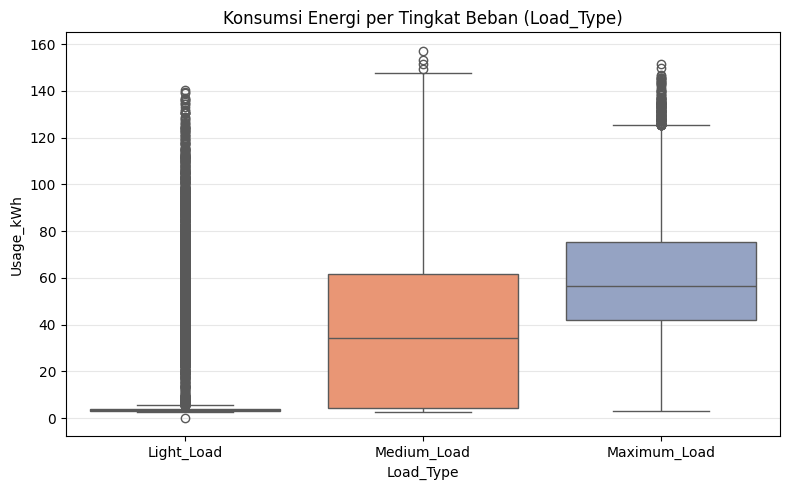

In [10]:
def plot_boxplot_kategori(
    df: pd.DataFrame,
    x_col: str = "Load_Type",
    y_col: str = "Usage_kWh",
    title: str = "Konsumsi Energi per Tingkat Beban (Load_Type)",
    xlabel: str | None = None,
    ylabel: str | None = None,
    order: list[str] | None = None,
    figsize: tuple[int, int] = (8, 5),
    palette: str = "Set2",
) -> None:
    """Menampilkan boxplot distribusi nilai numerik berdasarkan kategori tertentu."""
    fig, ax = plt.subplots(figsize=figsize)

    sns.boxplot(
        data=df,
        x=x_col,
        y=y_col,
        order=order,
        hue=x_col,
        palette=palette,
        legend=False,
        ax=ax,
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel if xlabel is not None else x_col)
    ax.set_ylabel(ylabel if ylabel is not None else y_col)
    ax.grid(True, axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()


plot_boxplot_kategori(
    df,
    x_col="Load_Type",
    y_col="Usage_kWh",
    order=["Light_Load", "Medium_Load", "Maximum_Load"],  # opsional: urutkan sesuai logika beban
)

**Interpretation:**

Boxplot ini memperlihatkan perbandingan distribusi konsumsi energi per interval (`Usage_kWh`) untuk tiga kategori `Load_Type`:

* **`Light_Load`:**
  - Mayoritas data mengumpul sangat rendah dan rapat di sekitar **~3–4 kWh** (kotak dan *whisker* bawah sangat tipis), namun memiliki **banyak *outlier* tinggi** yang menjulur hingga sekitar **140 kWh**. Artinya, label `Light_Load` lebih mencerminkan kondisi status/mode beban tertentu ketimbang nilai `Usage_kWh` yang selalu kecil.


* **`Medium_Load`:**
  - Rentang tengah (IQR) cukup lebar, kira-kira dari **~4 kWh (Q1)** hingga **~61 kWh (Q3)** dengan median sekitar **~34 kWh**, dan *whisker* atas mencapai **~147 kWh** serta sedikit *outlier* di atasnya (~150–157 kWh).


* **`Maximum_Load`:**
  - Memiliki median tertinggi (**~56 kWh**) dan rentang kuartil yang lebih terkonsentrasi di level tinggi (**~42 kWh** hingga **~75 kWh**), dengan batas *whisker* atas di sekitar **~125 kWh** dan *outlier* hingga **~152 kWh**.



**Intinya:**
  - Secara umum median `Usage_kWh` naik dari `Light_Load` → `Medium_Load` → `Maximum_Load`, tetapi `Light_Load` punya sebaran *outlier* ke atas yang sangat panjang—sehingga `Load_Type` tidak sepenuhnya selaras dengan besaran `Usage_kWh` secara linear.

### c) Average daily consumption over the course of a week (bars)

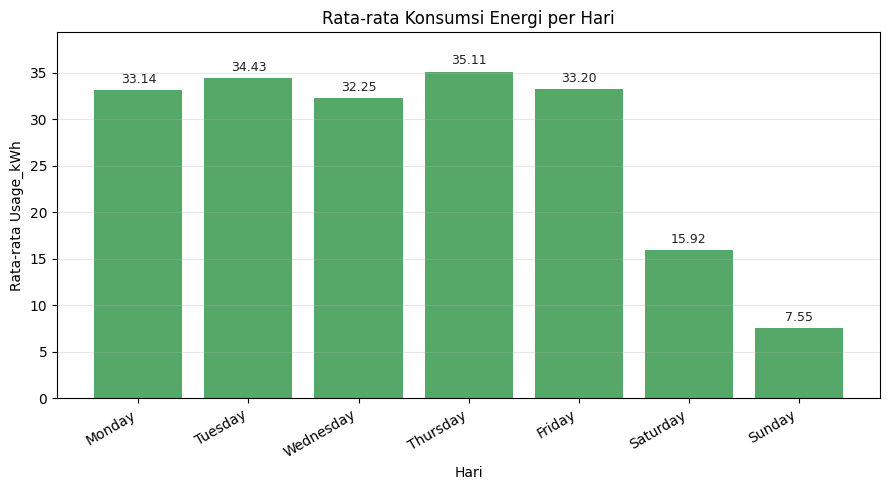

In [12]:
URUT_HARI = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]


def hitung_rata_rata_harian(
    df: pd.DataFrame,
    group_col: str = "Day_of_week",
    target_col: str = "Usage_kWh",
    agg_func: str = "mean",
    order: list[str] | None = URUT_HARI,
) -> pd.Series:
    """Menghitung statistik agregat per hari dalam seminggu dengan urutan kustom."""
    grouped = df.groupby(group_col)[target_col].agg(agg_func)
    if order is not None:
        valid_order = [label for label in order if label in grouped.index]
        grouped = grouped.reindex(valid_order)
    return grouped


def plot_bar_kategori(
    series: pd.Series,
    title: str,
    xlabel: str,
    ylabel: str,
    figsize: tuple[int, int] = (9, 5),
    color: str = "#55A868",
    rotation: int = 30,
    fmt: str = "{:.2f}",
    label_fontsize: float = 9,
) -> None:
    """Menampilkan grafik batang dengan label nilai di atas setiap bar."""
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar(series.index.astype(str), series.values, color=color)

    if len(series.values) > 0:
        max_val = float(pd.Series(series.values).max())
        ax.set_ylim(top=max_val * 1.12)

    ax.bar_label(
        bars,
        labels=[fmt.format(val) for val in series.values],
        padding=3,
        fontsize=label_fontsize,
        color="#222222",
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=rotation)
    for label in ax.get_xticklabels():
        label.set_ha("right" if rotation != 0 else "center")
    ax.grid(True, axis="y", alpha=0.3)

    fig.tight_layout()
    plt.show()


rata_hari = hitung_rata_rata_harian(df)
plot_bar_kategori(
    rata_hari,
    title="Rata-rata Konsumsi Energi per Hari",
    xlabel="Hari",
    ylabel="Rata-rata Usage_kWh",
    fmt="{:.2f}",  # ubah ke "{:.1f}" atau "{:.0f}" jika ingin lebih ringkas
)

**Interpretation:**

Grafik ini menunjukkan rata-rata konsumsi energi per interval (`Usage_kWh`) untuk setiap hari dalam seminggu:

* **Hari kerja (Senin–Jumat) tinggi dan stabil:**
  - Rata-rata berada di kisaran **32,25 hingga 35,11 kWh**, dengan **Kamis** tertinggi (**35,11 kWh**) diikuti **Selasa** (**34,43 kWh**).

* **Akhir pekan turun drastis:**
  - **Sabtu** turun lebih dari separuh menjadi **15,92 kWh**, lalu **Minggu** menjadi titik terendah di **7,55 kWh** (sekitar seperlima dari rata-rata hari kerja).

**Intinya:**
  - Pola ini mengonfirmasi bahwa beban listrik sangat dipengaruhi aktivitas operasional hari kerja dan melambat tajam saat akhir pekan.

### d) The link between consumption and CO₂ emissions

pearson_r: 0.9882
spearman_rho: 0.8815
slope: 0.0005
intercept: -0.0015
r_squared: 0.9765


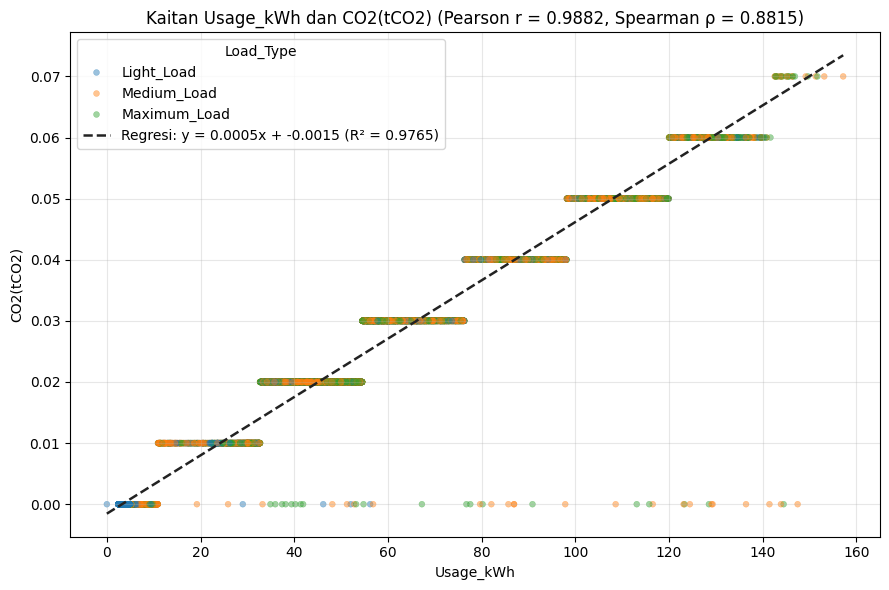

In [13]:
def hitung_kaitan_energi_co2(
    df: pd.DataFrame,
    x_col: str = "Usage_kWh",
    y_col: str = "CO2(tCO2)",
) -> dict[str, float]:
    """Menghitung korelasi Pearson, Spearman, dan parameter regresi linier sederhana."""
    clean_df = df[[x_col, y_col]].dropna()
    x = clean_df[x_col].to_numpy()
    y = clean_df[y_col].to_numpy()

    pearson_r = float(clean_df[x_col].corr(clean_df[y_col], method="pearson"))
    spearman_rho = float(clean_df[x_col].corr(clean_df[y_col], method="spearman"))

    slope, intercept = np.polyfit(x, y, deg=1)
    y_pred = slope * x + intercept
    ss_res = float(np.sum((y - y_pred) ** 2))
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    r2 = 1.0 - (ss_res / ss_tot) if ss_tot > 0 else np.nan

    return {
        "pearson_r": pearson_r,
        "spearman_rho": spearman_rho,
        "slope": float(slope),
        "intercept": float(intercept),
        "r_squared": float(r2),
    }


def plot_kaitan_energi_co2(
    df: pd.DataFrame,
    x_col: str = "Usage_kWh",
    y_col: str = "CO2(tCO2)",
    hue_col: str | None = "Load_Type",
    hue_order: list[str] | None = None,
    figsize: tuple[int, int] = (9, 6),
    alpha: float = 0.45,
    point_size: float = 18,
) -> None:
    """Menampilkan scatter plot kaitan Usage_kWh dan CO2(tCO2) lengkap dengan garis regresi."""
    stats = hitung_kaitan_energi_co2(df, x_col=x_col, y_col=y_col)
    clean_df = df.dropna(subset=[x_col, y_col]).copy()

    fig, ax = plt.subplots(figsize=figsize)

    sns.scatterplot(
        data=clean_df,
        x=x_col,
        y=y_col,
        hue=hue_col,
        hue_order=hue_order,
        alpha=alpha,
        s=point_size,
        edgecolor=None,
        ax=ax,
    )

    x_line = np.linspace(clean_df[x_col].min(), clean_df[x_col].max(), 200)
    y_line = stats["slope"] * x_line + stats["intercept"]
    ax.plot(
        x_line,
        y_line,
        color="#222222",
        linewidth=1.8,
        linestyle="--",
        label=(
            f"Regresi: y = {stats['slope']:.4f}x + {stats['intercept']:.4f} "
            f"(R² = {stats['r_squared']:.4f})"
        ),
    )

    ax.set_title(
        f"Kaitan {x_col} dan {y_col} "
        f"(Pearson r = {stats['pearson_r']:.4f}, Spearman ρ = {stats['spearman_rho']:.4f})"
    )
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.grid(True, alpha=0.3)
    ax.legend(title=hue_col if hue_col else None, loc="best")

    fig.tight_layout()
    plt.show()


ringkasan_kaitan = hitung_kaitan_energi_co2(df)
for metrik, nilai in ringkasan_kaitan.items():
    print(f"{metrik}: {nilai:.4f}")

plot_kaitan_energi_co2(
    df,
    hue_col="Load_Type",
    hue_order=["Light_Load", "Medium_Load", "Maximum_Load"],
)

**Interpretation:**

Grafik dan metrik statistik menunjukkan hubungan yang **sangat kuat dan hampir linier** antara konsumsi listrik (`Usage_kWh`) dan emisi karbon (`CO2(tCO2)`):

* **Hubungan sangat kuat (`pearson_r = 0.9882`, `r_squared = 0.9765`):**
  - Sekitar **97,65%** variasi `CO2(tCO2)` dapat dijelaskan secara linier oleh `Usage_kWh`—semakin besar pemakaian listrik, semakin tinggi pula emisi CO₂.


* **Pola bertingkat/diskret pada `CO2(tCO2)`:**
  - Titik-titik pada grafik membentuk garis horizontal berlapis pada kelipatan **0,01** (`0.00`, `0.01`, `0.02`, ..., `0.07` tCO₂), karena nilai `CO2(tCO2)` di dataset ini dibulatkan/terdiskritisasi ke dua angka desimal. Ini juga menjelaskan mengapa `spearman_rho` (**0,8815**) lebih rendah dibanding `pearson_r` (**0,9882**): banyak nilai berulang (*ties*) pada tingkat emisi yang sama untuk rentang `Usage_kWh` tertentu.


* **Kemiringan & *intercept* (`slope = 0.0005`, `intercept = -0.0015`):**
  - Setiap kenaikan **1 kWh** pemakaian rata-rata menambah sekitar **0,0005 tCO₂** (atau **0,5 kg CO₂**), sementara *intercept* kecil (`-0.0015`) mendekati nol dan merupakan efek samping regresi linier di area nilai rendah.


* **Peran `Load_Type`:**
  - Titik `Light_Load`, `Medium_Load`, dan `Maximum_Load` saling tumpang tindih mengikuti jalur regresi yang sama—artinya emisi lebih ditentukan oleh besarnya `Usage_kWh` aktual daripada sekadar label kategori bebannya.



**Intinya:**
  - `Usage_kWh` dan `CO2(tCO2)` bergerak hampir searah secara proporsional (dengan pembulatan 2 desimal pada `CO2(tCO2)`), sehingga `CO2(tCO2)` cenderung menjadi fitur yang sangat redundan/kolinear jika dipakai bersamaan dengan `Usage_kWh` pada model prediktif.

## Conclusions & Insights

Berdasarkan eksplorasi data yang telah dilakukan pada dataset konsumsi energi industri ini, berikut adalah kesimpulan utama dan rekomendasi operasional (*actionable insights*):


1. Pola Operasional Mingguan yang Kuat Temuan:
    - Rata-rata konsumsi energi per interval pada hari kerja (Senin–Jumat) stabil di kisaran 32,25–35,11 kWh (puncak di Kamis: 35,11 kWh), lalu turun tajam di akhir pekan menjadi 15,92 kWh (Sabtu) dan 7,55 kWh (Minggu).
    - Insight: Pola ini mengindikasikan aktivitas operasional/produksi padat pada hari kerja dan penurunan beban signifikan saat akhir pekan (misalnya karena jadwal maintenance atau pengurangan shift).


2. Perilaku Kategori Beban (Load_Type) & Outlier Light_LoadTemuan:
    - Median konsumsi naik bertahap dari Light_Load (3–4 kWh) → Medium_Load (34 kWh) → Maximum_Load (~56 kWh), tetapi Light_Load memiliki banyak outlier tinggi hingga sekitar 140 kWh.
    - Insight: Label Load_Type tidak selalu menggambarkan besaran daya yang rendah secara mutlak; lonjakan tinggi pada Light_Load bisa menandakan power surge sesaat, transisi beban, atau ketidakefisienan saat mesin menyala/beroperasi.

3. Hubungan Linier Sangat Kuat antara Usage_kWh dan CO2(tCO2)Temuan:
    - Korelasi Pearson mencapai 0,9882 dengan $R^2 = 0,9765$, dan kemiringan garis regresi sekitar 0,0005 tCO₂ per kWh (~0,5 kg CO₂/kWh).
    - Insight: Penurunan konsumsi listrik akan berdampak hampir sebanding pada emisi CO₂; sekaligus menjadi catatan bahwa CO2(tCO2) berpotensi redundan/kolinear jika dipakai bersama Usage_kWh pada model prediktif.


4. Rekomendasi AksiLoad / Peak Shifting:
    - Pertimbangkan memindahkan beban atau proses non-kritis yang fleksibel ke akhir pekan (jika sesuai jadwal operasional dan skema tarif listrik) untuk mengurangi tekanan beban di hari kerja.
    - Audit Outlier pada Light_Load: Periksa interval dengan Usage_kWh tinggi di bawah label Light_Load (beserta pola jam/NSM dan power factor-nya) untuk memastikan tidak ada pemborosan daya yang tidak terdeteksi.
